**JAWABAN TUGAS PENAMBANGAN DATA**

Nama pengerja : Shifa Rosdiana

Partner pembuat kasus : Erma Oktavia Ramadhani


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import missingno as msno
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, LabelEncoder, OrdinalEncoder
from sklearn.decomposition import PCA
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None); pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

df_raw = pd.read_csv('/content/drive/MyDrive/data /data_titanic_kotor.csv')
df = df_raw.copy()
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Fare_Rupiah,ID_Internal,Kapal
0,710,1,3.0,"Moubarek, Master. Halim Gonios (""William George"")",male,NaN,1,1,2661,15.2458,NaN,C,228687.0,82124,Titanic
1,440,0,2.0,"Kvillner, Mr. Johan Henrik Johannesson",Male,31.0,0,0,C.A. 18723,10.5000,NaN,S,157500.0,36790,Titanic
2,841,0,3.0,"ALHOMAKI, MR. ILMARI RUDOLF",male,20.0,0,0,SOTON/O2 3101287,7.9250,NaN,S,118875.0,35289,Titanic
3,721,1,2.0,"Harper, Miss. Annie Jessie ""Nina""",female,dua puluh,0,1,248727,1500.0000,NaN,S,22500000.0,65129,Titanic
4,40,1,3.0,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C,168626.0,25485,Titanic


1. DETEKSI MASALAH DATA


profil data

In [4]:
print('Dimensi :', df.shape)
print(); df.info()
display(df.describe(include='all').T)
print('\nMissing value per kolom:'); display(df.isna().sum().to_frame('missing'))

Dimensi : (208, 15)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  208 non-null    int64  
 1   Survived     208 non-null    int64  
 2   Pclass       197 non-null    float64
 3   Name         208 non-null    object 
 4   Sex          197 non-null    object 
 5   Age          169 non-null    object 
 6   SibSp        208 non-null    int64  
 7   Parch        208 non-null    int64  
 8   Ticket       208 non-null    object 
 9   Fare         197 non-null    float64
 10  Cabin        55 non-null     object 
 11  Embarked     208 non-null    object 
 12  Fare_Rupiah  197 non-null    float64
 13  ID_Internal  208 non-null    int64  
 14  Kapal        208 non-null    object 
dtypes: float64(3), int64(5), object(7)
memory usage: 24.5+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,208.0,NaN,NaN,NaN,434.923077,262.516646,6.0,213.5,417.5,662.25,890.0
Survived,208.0,NaN,NaN,NaN,0.413462,0.493642,0.0,0.0,0.0,1.0,1.0
Pclass,197.0,NaN,NaN,NaN,2.203046,0.874462,1.0,1.0,3.0,3.0,3.0
Name,208,200,"Nicola-Yarred, Miss. Jamila",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,197,6,male,116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,169,65,36.0,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SibSp,208.0,NaN,NaN,NaN,0.615385,2.849893,0.0,0.0,0.0,1.0,40.0
Parch,208.0,NaN,NaN,NaN,0.375,0.83043,0.0,0.0,0.0,0.0,5.0
Ticket,208,187,347088,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,197.0,NaN,NaN,NaN,14309.612245,82182.999975,0.0,8.05,20.525,52.0,853938.0



Missing value per kolom:


,missing
PassengerId,0
Survived,0
Pclass,11
Name,0
Sex,11
Age,39
SibSp,0
Parch,0
Ticket,0
Fare,11


Nilai unik kolom kategorik (repr agar spasi terlihat)

In [5]:
for c in ['Survived','Pclass','Sex','Embarked','Kapal']:
    print(f'--- {c} ---')
    print(df[c].map(repr).value_counts(dropna=False).to_dict(), '\n')

--- Survived ---
{'0': 122, '1': 86} 

--- Pclass ---
{'3.0': 99, '1.0': 59, '2.0': 39, 'nan': 11} 

--- Sex ---
{"'male'": 116, "'female'": 77, 'nan': 11, "'Male'": 1, "'MALE'": 1, "' female'": 1, "'FEMALE'": 1} 

--- Embarked ---
{"'S'": 139, "'C'": 48, "'Q'": 17, "'southampton'": 1, "'Cherbourg '": 1, "'s'": 1, "' q'": 1} 

--- Kapal ---
{"'Titanic'": 208} 



Kumpulkan semua masalah secara otomatis

In [6]:
issues = []
def add(kolom, jenis, n, bukti):
    if n > 0: issues.append({'Kolom':kolom,'Jenis masalah':jenis,'Baris terdampak':int(n),'Bukti':bukti})

### spasi berlebih (depan/belakang/ganda di tengah)
for c in df.select_dtypes('object').columns:
    s = df[c].dropna().astype(str)
    add(c,'Spasi depan/belakang', (s != s.str.strip()).sum(), 'repr() / s != s.str.strip()')
    add(c,'Spasi ganda di tengah', s.str.contains(r'\s{2,}').sum(), 'regex \\s{2,}')

### kategori tidak seragam
sex_ok = df['Sex'].astype(str).isin(['male','female']) | df['Sex'].isna()
add('Sex','Kategori tidak seragam (huruf besar/kecil/spasi/varian)', (~sex_ok).sum(), 'value_counts Sex')
emb_ok = df['Embarked'].astype(str).isin(['C','Q','S']) | df['Embarked'].isna()
add('Embarked','Kategori tidak seragam', (~emb_ok).sum(), 'value_counts Embarked')

### tipe data salah: kolom yang seharusnya numerik tetapi berisi teks
num_cols = ['PassengerId','Survived','Pclass','Age','SibSp','Parch','Fare','Fare_Rupiah']
for c in num_cols:
    conv = pd.to_numeric(df[c], errors='coerce')
    bad = df[c].notna() & conv.isna()
    add(c,'Tipe data salah / format teks (mis. "22 tahun")', bad.sum(), f'dtype={df[c].dtype}; contoh: {df.loc[bad,c].head(3).tolist()}')
    if df[c].dtype == object and conv.notna().sum() > 0:
        add(c,'Kolom bertipe object padahal numerik', df[c].notna().sum(), 'df.dtypes')
num = {c: pd.to_numeric(df[c], errors='coerce') for c in num_cols}

### pelanggaran aturan validasi
rules = {'Age':(0,80),'Fare':(0,520),'SibSp':(0,8),'Parch':(0,6)}
for c,(lo,hi) in rules.items():
    v = num[c].notna() & ((num[c] < lo) | (num[c] > hi))
    add(c,f'Di luar rentang valid {lo}-{hi} (outlier/invalid)', v.sum(), f'boxplot; nilai: {sorted(num[c][v].unique().tolist())[:6]}')
v = num['Pclass'].notna() & ~num['Pclass'].isin([1,2,3])
add('Pclass','Bukan 1/2/3', v.sum(), 'value_counts')
v = num['Pclass'].notna() & (num['Pclass'] % 1 != 0)
add('Pclass','Bukan bilangan bulat', v.sum(), 'value_counts')
v = num['Survived'].notna() & ~num['Survived'].isin([0,1])
add('Survived','Bukan 0/1', v.sum(), 'value_counts')

### format Name "Nama Belakang, Gelar. Nama Depan"
nm = df['Name'].dropna().astype(str).str.strip().str.replace(r'\s+',' ',regex=True)
add('Name','Format tidak sesuai aturan', (~nm.str.match(r'^[^,]+, [A-Za-z ]+\. .+$')).sum(), 'regex Name')

### duplikat
add('(seluruh baris)','Data ganda (baris identik)', df.duplicated().sum(), 'df.duplicated()')
add('PassengerId','PassengerId ganda', df['PassengerId'].duplicated().sum(), 'duplicated()')

### satuan Fare tidak seragam (Fare vs Fare_Rupiah/15000)
fr = num['Fare_Rupiah']/15000
mis = num['Fare'].notna() & fr.notna() & ((num['Fare']-fr).abs() > 0.5)
add('Fare','Satuan tidak seragam / tidak konsisten dengan Fare_Rupiah/15000', mis.sum(), 'selisih Fare vs Fare_Rupiah/15000')

### kolom tidak berguna
add('ID_Internal','Kolom tidak berguna (kode internal, unik/tidak informatif)', len(df), f'nunique={df.ID_Internal.nunique()}')
add('Kapal','Kolom tidak berguna (konstan)', len(df), f'nunique={df.Kapal.nunique()} -> {df.Kapal.unique()[:3]}')
add('Fare_Rupiah','Kolom redundan dengan Fare (beda satuan)', len(df), 'Fare_Rupiah = Fare x 15000')
add('Ticket','Kardinalitas tinggi, kurang berguna', len(df), f'nunique={df.Ticket.nunique()}')
add('PassengerId','Hanya identitas, bukan fitur prediktif', len(df), 'ID unik')
add('Cabin','Missing value sangat banyak', df.Cabin.isna().sum(), f'{df.Cabin.isna().mean():.0%} kosong')

### missing value
for c in df.columns[df.isna().any()]:
    if c != 'Cabin': add(c,'Missing value', df[c].isna().sum(), 'isna().sum()')

tabel_masalah = pd.DataFrame(issues)
display(tabel_masalah)

,Kolom,Jenis masalah,Baris terdampak,Bukti
0,Name,Spasi depan/belakang,3,repr() / s != s.str.strip()
1,Name,Spasi ganda di tengah,3,"regex \s{2,}"
2,Sex,Spasi depan/belakang,1,repr() / s != s.str.strip()
3,Embarked,Spasi depan/belakang,2,repr() / s != s.str.strip()
4,Sex,Kategori tidak seragam (huruf besar/kecil/spas...,4,value_counts Sex
5,Embarked,Kategori tidak seragam,4,value_counts Embarked
6,Age,"Tipe data salah / format teks (mis. ""22 tahun"")",3,"dtype=object; contoh: ['dua puluh', '30 tahun'..."
7,Age,Kolom bertipe object padahal numerik,169,df.dtypes
8,Age,Di luar rentang valid 0-80 (outlier/invalid),5,"boxplot; nilai: [-12.0, -5.0, 150.0, 240.0]"
9,Fare,Di luar rentang valid 0-520 (outlier/invalid),13,"boxplot; nilai: [999.0, 1500.0, 2200.0, 116062..."


Bukti visual (histogram & boxplot)

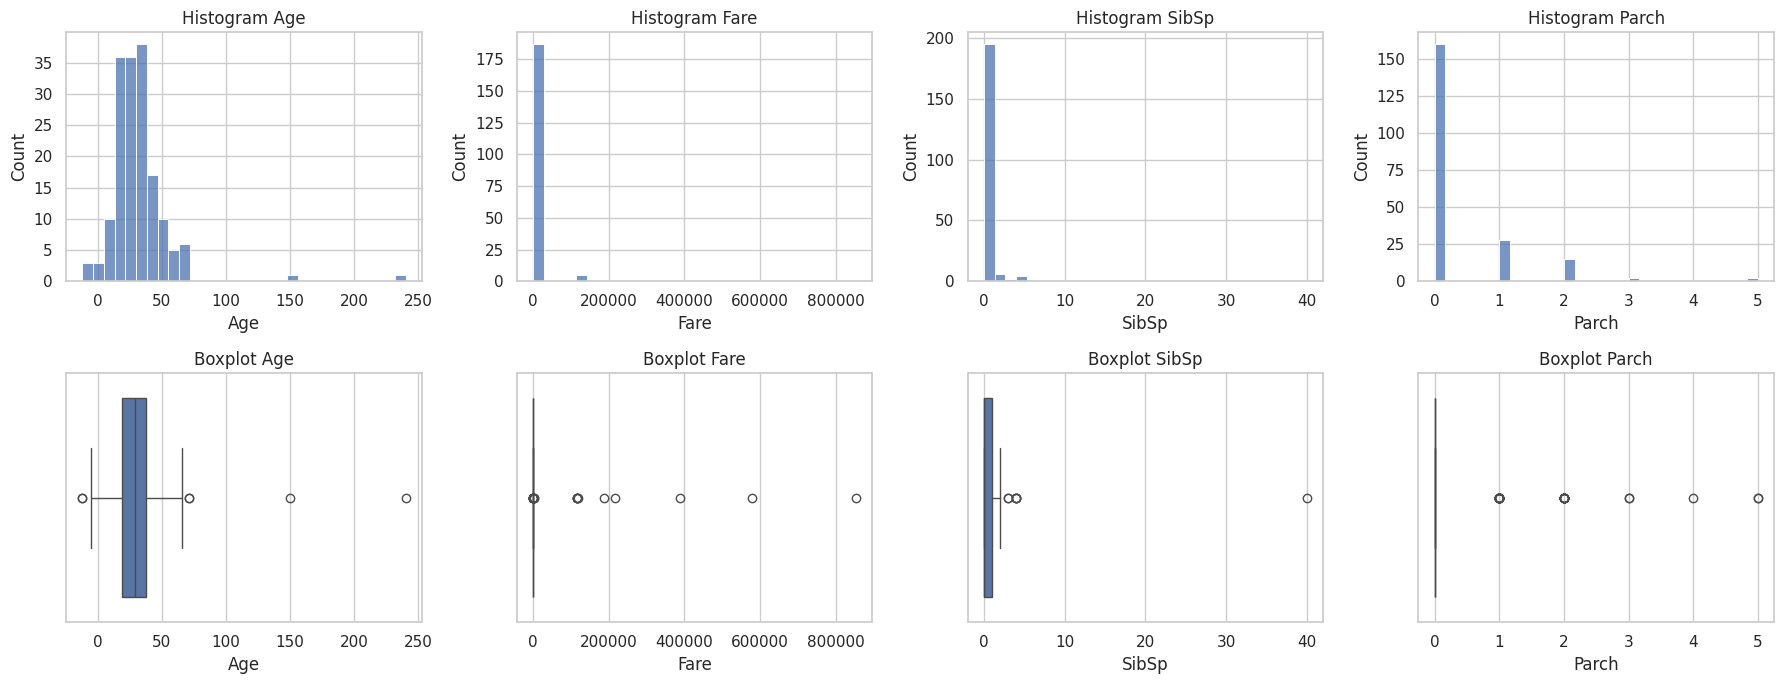

In [7]:
fig, ax = plt.subplots(2, 4, figsize=(18,7))
for i,c in enumerate(['Age','Fare','SibSp','Parch']):
    sns.histplot(num[c].dropna(), bins=30, ax=ax[0,i]).set_title(f'Histogram {c}')
    sns.boxplot(x=num[c].dropna(), ax=ax[1,i]).set_title(f'Boxplot {c}')
plt.tight_layout(); plt.show()

2. PEMBERSIHAN DATA

Spasi berlebih

In [8]:
def tidy(x): return re.sub(r'\s+',' ',x).strip() if isinstance(x,str) else x
before = df[['Sex','Embarked','Name']].head(60)[lambda d: d.apply(lambda s: s.astype(str).str.contains(r'^\s|\s$|\s{2,}')).any(axis=1)].head(5)
print('SEBELUM:'); display(before.map(repr))
for c in df.select_dtypes('object').columns: df[c] = df[c].map(tidy)
print('SESUDAH:'); display(df.loc[before.index, ['Sex','Embarked','Name']].map(repr))

SEBELUM:


,Sex,Embarked,Name
2,'male','S',"' ALHOMAKI, MR. ILMARI RUDOLF '"
11,'male','S',"' KELLY, MR. JAMES '"
24,' female','S',"'Risien, Mr. Samuel Beard'"
30,'male','Cherbourg ',"'Petroff, Mr. Nedelio'"
33,'female','S',"' HARKNETT, MISS. ALICE PHOEBE '"


SESUDAH:


,Sex,Embarked,Name
2,'male','S',"'ALHOMAKI, MR. ILMARI RUDOLF'"
11,'male','S',"'KELLY, MR. JAMES'"
24,'female','S',"'Risien, Mr. Samuel Beard'"
30,'male','Cherbourg',"'Petroff, Mr. Nedelio'"
33,'female','S',"'HARKNETT, MISS. ALICE PHOEBE'"


Keseragaman kategori (Sex, Embarked) dan format Name

In [9]:
print('Sex sebelum     :', df['Sex'].value_counts(dropna=False).to_dict())
print('Embarked sebelum:', df['Embarked'].value_counts(dropna=False).to_dict())

sex_map = {'male':'male','m':'male','laki-laki':'male','pria':'male','female':'female','f':'female','perempuan':'female','wanita':'female'}
emb_map = {'c':'C','cherbourg':'C','q':'Q','queenstown':'Q','s':'S','southampton':'S'}
s_low = df['Sex'].str.lower(); e_low = df['Embarked'].str.lower()
print('Varian Sex tak terpetakan     :', s_low[s_low.notna() & ~s_low.isin(sex_map)].unique())
print('Varian Embarked tak terpetakan:', e_low[e_low.notna() & ~e_low.isin(emb_map)].unique())
df['Sex'] = s_low.map(sex_map)
df['Embarked'] = e_low.map(emb_map)

def fix_name(n):
    if not isinstance(n,str): return n
    if n.isupper() or n.islower(): n = n.title()
    return n
df['Name'] = df['Name'].map(fix_name)

print('\nSex sesudah     :', df['Sex'].value_counts(dropna=False).to_dict())
print('Embarked sesudah:', df['Embarked'].value_counts(dropna=False).to_dict())
nm_bad = ~df['Name'].dropna().str.match(r'^[^,]+, [A-Za-z ]+\. .+$')
print('Name masih tidak sesuai format:', nm_bad.sum())
display(df.loc[nm_bad[nm_bad].index, 'Name'].head())

Sex sebelum     : {'male': 116, 'female': 78, nan: 11, 'Male': 1, 'MALE': 1, 'FEMALE': 1}
Embarked sebelum: {'S': 139, 'C': 48, 'Q': 17, 'southampton': 1, 'Cherbourg': 1, 's': 1, 'q': 1}
Varian Sex tak terpetakan     : []
Varian Embarked tak terpetakan: []

Sex sesudah     : {'male': 118, 'female': 79, nan: 11}
Embarked sesudah: {'S': 141, 'C': 49, 'Q': 18}
Name masih tidak sesuai format: 0


,Name


perbaikan tipe data

In [10]:
def to_num(s):
    t = s.astype(str).str.replace(',', '.', regex=False).str.extract(r'(-?\d+\.?\d*)')[0]
    return pd.to_numeric(t, errors='coerce')

print('Dtype sebelum:'); print(df[['Survived','Pclass','Age','Fare','SibSp','Parch','Fare_Rupiah']].dtypes.to_dict())
for c in ['Survived','Pclass','Age','Fare','SibSp','Parch']:
    df[c] = to_num(df[c])
df['Fare_Rupiah'] = pd.to_numeric(df['Fare_Rupiah'].astype(str).str.replace(r'[^\d.]','',regex=True), errors='coerce')
df['PassengerId'] = pd.to_numeric(df['PassengerId'], errors='coerce')
print('Dtype sesudah:'); print(df[['Survived','Pclass','Age','Fare','SibSp','Parch','Fare_Rupiah']].dtypes.to_dict())


Dtype sebelum:
{'Survived': dtype('int64'), 'Pclass': dtype('float64'), 'Age': dtype('O'), 'Fare': dtype('float64'), 'SibSp': dtype('int64'), 'Parch': dtype('int64'), 'Fare_Rupiah': dtype('float64')}
Dtype sesudah:
{'Survived': dtype('int64'), 'Pclass': dtype('float64'), 'Age': dtype('float64'), 'Fare': dtype('float64'), 'SibSp': dtype('int64'), 'Parch': dtype('int64'), 'Fare_Rupiah': dtype('float64')}


Hapus data ganda

In [11]:
print('Baris sebelum:', len(df))
print('Duplikat identik:', df.duplicated().sum(), '| PassengerId ganda:', df['PassengerId'].duplicated().sum())
display(df[df['PassengerId'].duplicated(keep=False)].sort_values('PassengerId').head(6))
df = df.drop_duplicates()                                   # baris identik
df = df.drop_duplicates(subset='PassengerId', keep='first') # satu penumpang satu baris
df = df.reset_index(drop=True)
print('Baris sesudah:', len(df))

Baris sebelum: 208
Duplikat identik: 8 | PassengerId ganda: 8


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Fare_Rupiah,ID_Internal,Kapal
4,40,1,3.0,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C,168626.0,25485,Titanic
207,40,1,3.0,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C,168626.0,25485,Titanic
204,119,0,1.0,"Baxter, Mr. Quigg Edmond",male,24.0,0,1,PC 17558,247.5208,B58 B60,C,3712812.0,83477,Titanic
184,119,0,1.0,"Baxter, Mr. Quigg Edmond",male,24.0,0,1,PC 17558,247.5208,B58 B60,C,3712812.0,83477,Titanic
40,121,0,2.0,"Hickman, Mr. Stanley George",NaN,-12.0,2,0,S.O.C. 14879,73.5000,NaN,S,1102500.0,48413,Titanic
201,121,0,2.0,"Hickman, Mr. Stanley George",NaN,-12.0,2,0,S.O.C. 14879,73.5000,NaN,S,1102500.0,48413,Titanic


Baris sesudah: 200


Seragamkan satuan Fare (poundsterling)

In [12]:
fr = df['Fare_Rupiah']/15000
mism = df['Fare_Rupiah'].notna() & (df['Fare'].isna() | ((df['Fare']-fr).abs() > 0.5))
print('Fare tidak konsisten dengan Fare_Rupiah:', mism.sum())
cmp_before = df.loc[mism, ['PassengerId','Fare','Fare_Rupiah']].head(8)
df.loc[mism, 'Fare'] = fr[mism]                              # Fare_Rupiah dijadikan acuan
big = (df['Fare'] >= 1000) & df['Fare_Rupiah'].isna()          # kemungkinan masih dalam Rupiah
print('Fare >= 1000 tanpa Fare_Rupiah (dibagi 15000):', big.sum())
df.loc[big, 'Fare'] = df.loc[big,'Fare']/15000
print('SEBELUM:'); display(cmp_before)
print('SESUDAH:'); display(df.loc[cmp_before.index, ['PassengerId','Fare','Fare_Rupiah']])

Fare tidak konsisten dengan Fare_Rupiah: 10
Fare >= 1000 tanpa Fare_Rupiah (dibagi 15000): 0
SEBELUM:


,PassengerId,Fare,Fare_Rupiah
17,654,117438.0,117438.0
35,621,216813.0,216813.0
83,779,116062.5,116062.0
105,443,116625.0,116625.0
107,463,577500.0,577500.0
126,797,388938.0,388938.0
133,778,187125.0,187125.0
134,600,853938.0,853938.0


SESUDAH:


,PassengerId,Fare,Fare_Rupiah
17,654,7.829200,117438.0
35,621,14.454200,216813.0
83,779,7.737467,116062.0
105,443,7.775000,116625.0
107,463,38.500000,577500.0
126,797,25.929200,388938.0
133,778,12.475000,187125.0
134,600,56.929200,853938.0


Nilai melanggar aturan validasi NaN

In [13]:
rules = {'Age':(0,80),'Fare':(0,520),'SibSp':(0,8),'Parch':(0,6)}
ringkas = []
for c,(lo,hi) in rules.items():
    v = df[c].notna() & ((df[c] < lo) | (df[c] > hi))
    ringkas.append((c, int(v.sum()), sorted(df.loc[v,c].unique().tolist())[:6]))
    df.loc[v, c] = np.nan
v = ~df['Pclass'].isin([1,2,3]) & df['Pclass'].notna();   ringkas.append(('Pclass', int(v.sum()), df.loc[v,'Pclass'].unique().tolist())); df.loc[v,'Pclass'] = np.nan
v = ~df['Survived'].isin([0,1]) & df['Survived'].notna(); ringkas.append(('Survived', int(v.sum()), df.loc[v,'Survived'].unique().tolist())); df.loc[v,'Survived'] = np.nan
display(pd.DataFrame(ringkas, columns=['Kolom','Jumlah diubah ke NaN','Nilai pelanggar']))
print('Catatan: Fare maksimum valid (<=520) dipertahankan; outlier tinggi yang valid bukan kesalahan data.')

,Kolom,Jumlah diubah ke NaN,Nilai pelanggar
0,Age,4,"[-12.0, -5.0, 150.0, 240.0]"
1,Fare,3,"[999.0, 1500.0, 2200.0]"
2,SibSp,1,[40]
3,Parch,0,[]
4,Pclass,0,[]
5,Survived,0,[]


Catatan: Fare maksimum valid (<=520) dipertahankan; outlier tinggi yang valid bukan kesalahan data.


Buang kolom tidak berguna


In [14]:
drop_cols = ['ID_Internal','Kapal','Fare_Rupiah']   # Fare_Rupiah sudah diserap ke Fare
print('Dibuang:', drop_cols, '| Ticket dibuang di tahap 5 (dipertahankan dulu untuk dokumentasi)')
df = df.drop(columns=drop_cols)
display(df.describe(include='all').T)

Dibuang: ['ID_Internal', 'Kapal', 'Fare_Rupiah'] | Ticket dibuang di tahap 5 (dipertahankan dulu untuk dokumentasi)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,200.0,NaN,NaN,NaN,442.055,261.749779,6.0,225.75,430.5,669.25,890.0
Survived,200.0,NaN,NaN,NaN,0.405,0.492124,0.0,0.0,0.0,1.0,1.0
Pclass,190.0,NaN,NaN,NaN,2.205263,0.875881,1.0,1.0,3.0,3.0,3.0
Name,200,200,"Moubarek, Master. Halim Gonios (""William George"")",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,190,2,male,115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,155.0,NaN,NaN,NaN,30.544065,14.381459,0.83,20.0,29.0,38.0,71.0
SibSp,199.0,NaN,NaN,NaN,0.417085,0.773232,0.0,0.0,0.0,1.0,4.0
Parch,200.0,NaN,NaN,NaN,0.385,0.842809,0.0,0.0,0.0,0.0,5.0
Ticket,200,187,347088,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,187.0,NaN,NaN,NaN,32.595788,44.215432,0.0,7.9104,15.2458,31.33125,262.375


3. PENANGANAN MISSING VALUE

,missing,persen
Cabin,148,74.0
Age,45,22.5
Fare,13,6.5
Pclass,10,5.0
Sex,10,5.0
SibSp,1,0.5


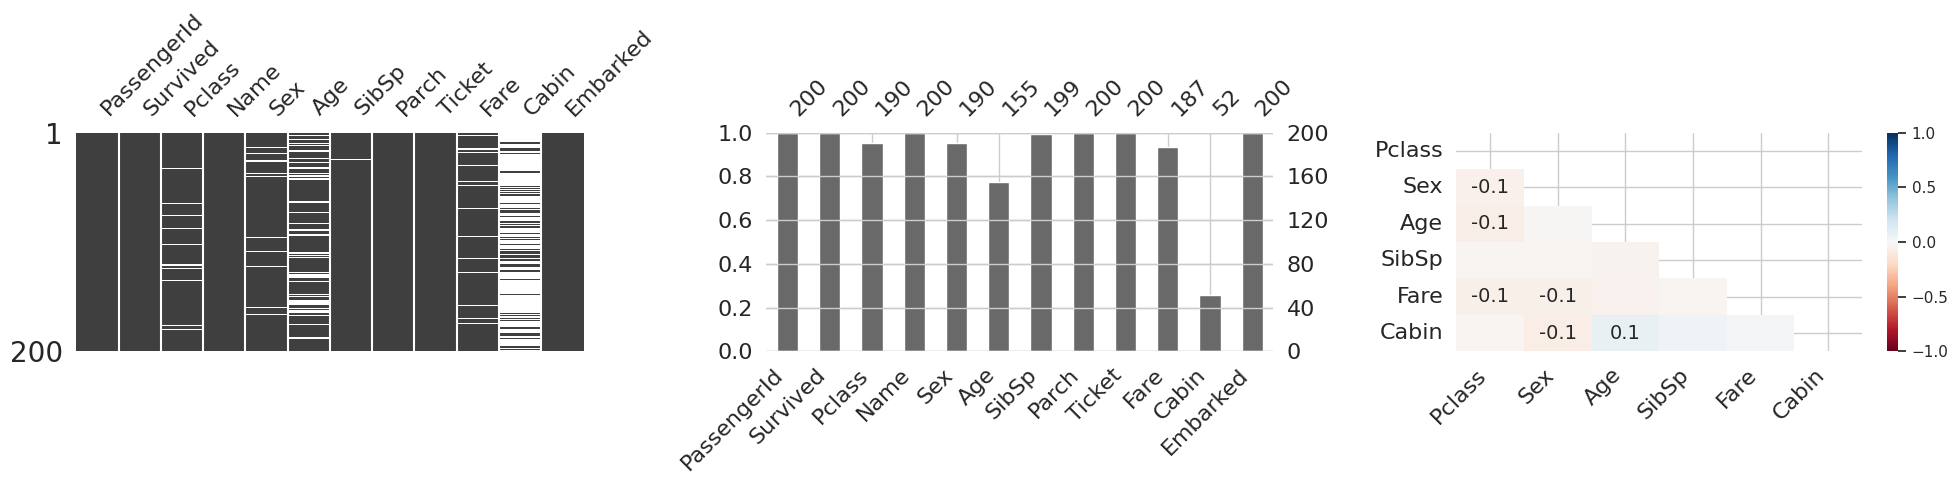

In [15]:
miss = pd.DataFrame({'missing':df.isna().sum(), 'persen':(df.isna().mean()*100).round(1)})
display(miss[miss.missing>0].sort_values('missing', ascending=False))
fig,ax = plt.subplots(1,3,figsize=(20,5))
msno.matrix(df, ax=ax[0], sparkline=False); msno.bar(df, ax=ax[1]); msno.heatmap(df, ax=ax[2])
plt.tight_layout(); plt.show()

Statistik deskriptif penentu metode

Age: mean=30.54 median=29.00 modus=36.0 skew=0.60
Fare: mean=32.60 median=15.25 modus=13.0 skew=3.23
Embarked: {'S': 0.68, 'C': 0.23, 'Q': 0.09}


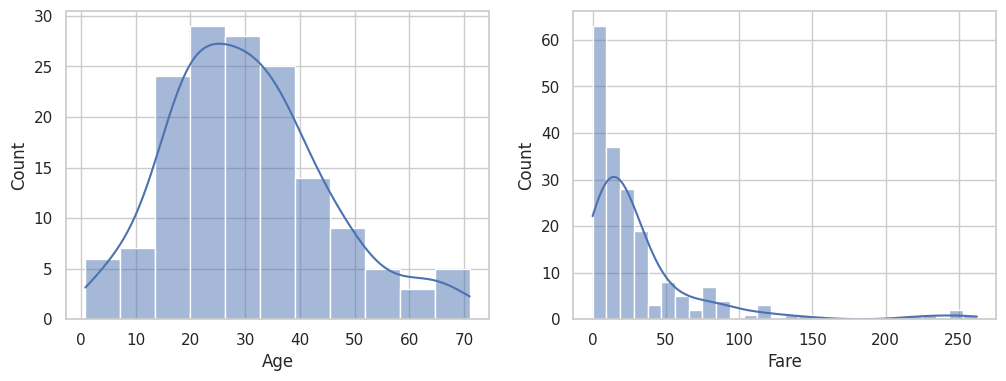

In [16]:
for c in ['Age','Fare']:
    s = df[c].dropna()
    print(f'{c}: mean={s.mean():.2f} median={s.median():.2f} modus={s.mode().iloc[0]} skew={s.skew():.2f}')
print('Embarked:', df['Embarked'].value_counts(normalize=True).round(3).to_dict())
fig,ax = plt.subplots(1,2,figsize=(12,4))
sns.histplot(df['Age'].dropna(), kde=True, ax=ax[0]); sns.histplot(df['Fare'].dropna(), kde=True, ax=ax[1]); plt.show()

Perbandingan ≥3 strategi

In [17]:
rows = []
def rec(col, name, s, n_rows):
    rows.append({'Kolom':col,'Strategi':name,'Jumlah baris data':n_rows,'Mean':round(s.mean(),3),'Median':round(s.median(),3),'Std':round(s.std(),3)})

for c in ['Age','Fare']:
    s = df[c]
    rec(c,'Asli (tanpa imputasi)', s.dropna(), len(s.dropna()))
    rec(c,'Hapus baris', df.dropna(subset=[c])[c], len(df.dropna(subset=[c])))
    rec(c,'Isi 0', s.fillna(0), len(s))
    rec(c,'Isi mean', s.fillna(s.mean()), len(s))
    rec(c,'Isi median', s.fillna(s.median()), len(s))
display(pd.DataFrame(rows))
print('Hapus baris dengan missing di kolom MANA PUN :', df.dropna().shape, '(Cabin membuat hampir semua baris hilang)')
print('Hapus kolom yang punya missing               :', df.dropna(axis=1).shape)
e = df['Embarked']
print('\nEmbarked: modus =', e.mode().iloc[0], '| hapus baris ->', len(df.dropna(subset=['Embarked'])), 'baris | isi modus ->', len(e))

,Kolom,Strategi,Jumlah baris data,Mean,Median,Std
0,Age,Asli (tanpa imputasi),155,30.544,29.000,14.381
1,Age,Hapus baris,155,30.544,29.000,14.381
2,Age,Isi 0,200,23.672,23.250,17.988
3,Age,Isi mean,200,30.544,30.544,12.651
4,Age,Isi median,200,30.197,29.000,12.668
5,Fare,Asli (tanpa imputasi),187,32.596,15.246,44.215
6,Fare,Hapus baris,187,32.596,15.246,44.215
7,Fare,Isi 0,200,30.477,13.000,43.499
8,Fare,Isi mean,200,32.596,18.629,42.747
9,Fare,Isi median,200,31.468,15.246,42.961


Hapus baris dengan missing di kolom MANA PUN : (33, 12) (Cabin membuat hampir semua baris hilang)
Hapus kolom yang punya missing               : (200, 6)

Embarked: modus = S | hapus baris -> 200 baris | isi modus -> 200


**Dampak strategi**: hapus baris mengurangi sampel; hapus kolom membuang informasi penting (Age, Fare prediktif); isi 0 menurunkan mean dan menambah varians palsu (usia 0 tahun tidak realistis); isi mean mengecilkan std dan sensitif outlier; isi median lebih robust, terutama untuk Fare yang miring ke kanan; modus cocok untuk kategorik (Embarked).

Strategi final

In [18]:
df = df.dropna(subset=['Survived']).reset_index(drop=True)
for c in ['Pclass','Sex','Embarked']: df[c] = df[c].fillna(df[c].mode().iloc[0])   # modus
for c in ['SibSp','Parch']:           df[c] = df[c].fillna(df[c].median())         # median (diskrit, dominan 0)
df['Fare'] = df['Fare'].fillna(df.groupby('Pclass')['Fare'].transform('median'))  # median per kelas (Fare sangat miring)
print('Missing setelah strategi dasar:'); display(df.isna().sum()[lambda s: s>0].to_frame('missing'))

Missing setelah strategi dasar:


,missing
Age,45
Cabin,148


| Kolom | Strategi final | Alasan |
|---|---|---|
| Survived | hapus baris | variabel target, tidak boleh diisi |
| Pclass, Sex, Embarked | modus | kategorik |
| SibSp, Parch | median | diskrit, mayoritas 0 |
| Fare | median per Pclass | distribusi sangat miring, tarif bergantung kelas |
| Age | **median per Pclass × Sex** (tantangan) | usia berbeda antar kelompok |
| Cabin | tidak diimputasi, diubah jadi fitur (tahap 4) | ±77% kosong; kekosongan itu sendiri informatif |

TANTANGAN – Imputasi Age berdasarkan Pclass & Sex

Median Age per Pclass x Sex:


median         mean        count     
Sex    female  male female  male female male
Pclass                                      
1.0      30.5  45.0   32.8  43.2     16   27
2.0      34.5  31.0   31.8  30.9     16   17
3.0      19.0  25.0   23.1  26.6     26   53

,MAE,RMSE
Mean global,12.202,15.671
Median global,12.328,15.856
Median per Pclass x Sex,10.602,13.439


,Asli,Isi mean,Isi median,Isi per Pclass x Sex
count,155.00,200.00,200.00,200.00
mean,30.54,30.54,30.20,30.06
std,14.38,12.65,12.67,13.27
min,0.83,0.83,0.83,0.83
25%,20.00,23.00,23.00,20.88
50%,29.00,30.54,29.00,28.50
75%,38.00,36.00,36.00,37.25
max,71.00,71.00,71.00,71.00


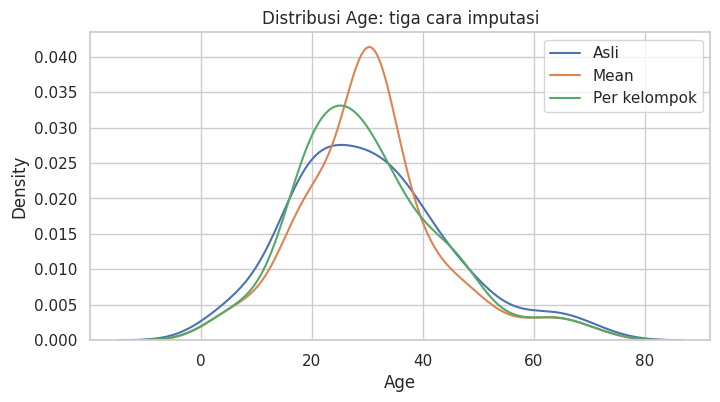

In [19]:
print('Median Age per Pclass x Sex:'); display(df.pivot_table(index='Pclass', columns='Sex', values='Age', aggfunc=['median','mean','count']).round(1))

known = df[df['Age'].notna()].copy()
rng = np.random.default_rng(42)
idx = rng.choice(known.index, size=max(1,int(0.2*len(known))), replace=False)
tmp = known.copy(); truth = tmp.loc[idx,'Age'].copy(); tmp.loc[idx,'Age'] = np.nan
p_mean   = pd.Series(tmp['Age'].mean(),   index=idx)
p_median = pd.Series(tmp['Age'].median(), index=idx)
p_group  = tmp.groupby(['Pclass','Sex'])['Age'].transform('median')[idx].fillna(tmp['Age'].median())
hasil = pd.DataFrame({'MAE':[(truth-p_mean).abs().mean(),(truth-p_median).abs().mean(),(truth-p_group).abs().mean()],
                      'RMSE':[np.sqrt(((truth-p)**2).mean()) for p in (p_mean,p_median,p_group)]},
                     index=['Mean global','Median global','Median per Pclass x Sex']).round(3)
display(hasil)

# Penerapan ke data sebenarnya
age_before = df['Age'].copy()
grp = df.groupby(['Pclass','Sex'])['Age'].transform('median')
df['Age'] = df['Age'].fillna(grp).fillna(df['Age'].median())
perb = pd.DataFrame({'Asli':age_before.describe(),
                     'Isi mean':age_before.fillna(age_before.mean()).describe(),
                     'Isi median':age_before.fillna(age_before.median()).describe(),
                     'Isi per Pclass x Sex':df['Age'].describe()}).round(2)
display(perb)
fig,ax = plt.subplots(figsize=(8,4))
for lbl,s in [('Asli',age_before.dropna()),('Mean',age_before.fillna(age_before.mean())),('Per kelompok',df['Age'])]:
    sns.kdeplot(s, label=lbl, ax=ax)
ax.legend(); ax.set_title('Distribusi Age: tiga cara imputasi'); plt.show()

Mengapa per kelompok lebih tepat? Usia tidak homogen: penumpang kelas 1 cenderung lebih tua daripada kelas 3, dan usia berbeda antar jenis kelamin. Mengisi dengan satu angka global memberi semua penumpang usia yang sama sehingga distribusi menumpuk di satu titik (std mengecil, bias). Imputasi per Pclass×Sex mempertahankan struktur data dan memberi galat (MAE/RMSE) yang lebih kecil pada uji penyembunyian di atas.

4. TRANSFORMASI DATA

Normalisasi: Min-Max, Z-score, Robust

,asli_count,asli_mean,asli_std,asli_min,asli_25%,asli_50%,asli_75%,asli_max
Age,200.0,30.057,13.269,0.83,20.875,28.500,37.250,71.000
Fare,200.0,31.734,43.118,0.00,8.050,14.454,31.303,262.375
SibSp,200.0,0.415,0.772,0.00,0.000,0.000,1.000,4.000
Parch,200.0,0.385,0.843,0.00,0.000,0.000,0.000,5.000


MinMax


,mean,std,min,50%,max
Age,0.417,0.189,0.0,0.394,1.0
Fare,0.121,0.164,0.0,0.055,1.0
SibSp,0.104,0.193,0.0,0.000,1.0
Parch,0.077,0.169,0.0,0.000,1.0


Z-score


,mean,std,min,50%,max
Age,-0.0,1.003,-2.208,-0.118,3.093
Fare,-0.0,1.003,-0.738,-0.402,5.362
SibSp,-0.0,1.003,-0.539,-0.539,4.656
Parch,-0.0,1.003,-0.458,-0.458,5.489


Robust


,mean,std,min,50%,max
Age,0.095,0.810,-1.690,0.0,2.595
Fare,0.743,1.854,-0.622,0.0,10.662
SibSp,0.415,0.772,0.000,0.0,4.000
Parch,0.385,0.843,0.000,0.0,5.000


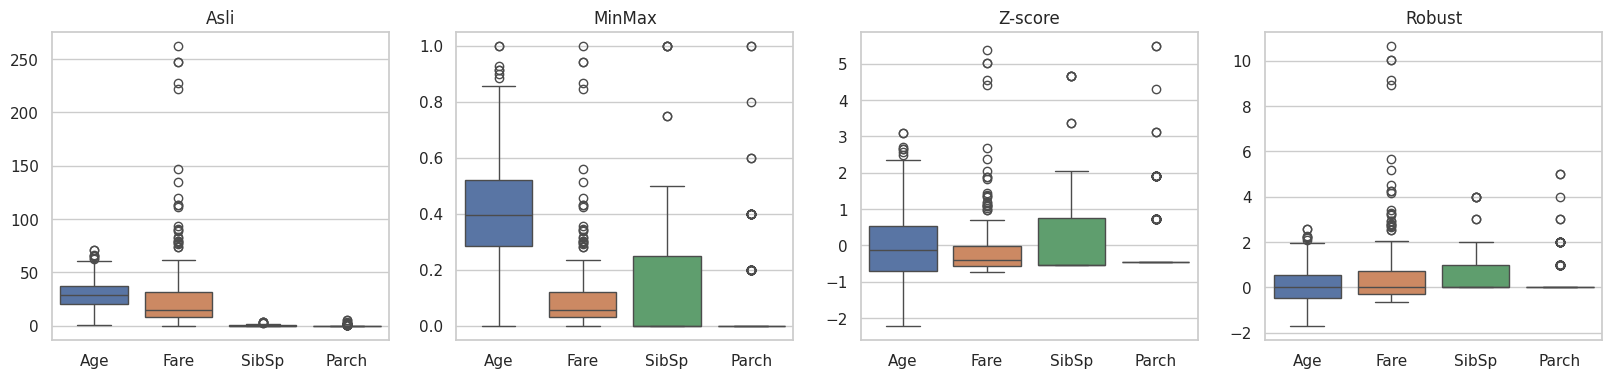

In [20]:
cols = ['Age','Fare','SibSp','Parch']
X = df[cols].astype(float)
sc = {'MinMax':MinMaxScaler(),'Z-score':StandardScaler(),'Robust':RobustScaler()}
scaled = {k: pd.DataFrame(v.fit_transform(X), columns=cols) for k,v in sc.items()}
display(X.describe().T.round(3).add_prefix('asli_'))
for k,v in scaled.items(): print(k); display(v.describe().T[['mean','std','min','50%','max']].round(3))
fig,ax = plt.subplots(1,4,figsize=(20,4))
for a,(k,v) in zip(ax,[('Asli',X)]+list(scaled.items())):
    sns.boxplot(data=v, ax=a); a.set_title(k)
plt.show()

Perbandingan: Min-Max memetakan ke [0,1] tetapi peka outlier (Fare). Z-score berpusat di 0 dengan std 1, cocok untuk PCA/regresi, tetapi mean/std ikut tertarik outlier. Robust Scaler memakai median & IQR sehingga paling tahan outlier (Fare, SibSp, Parch); rentangnya tidak dibatasi.

Encoding

In [21]:
df_t = df.copy()
df_t['Pclass_enc'] = OrdinalEncoder(categories=[[1,2,3]]).fit_transform(df_t[['Pclass']]).astype(int).ravel()   # ordinal 0,1,2
df_t['Survived_enc'] = LabelEncoder().fit_transform(df_t['Survived'].astype(int))
df_t['Sex_enc'] = df_t['Sex'].map({'male':0,'female':1})                       # biner
df_t = pd.concat([df_t, pd.get_dummies(df_t['Embarked'], prefix='Embarked', dtype=int)], axis=1)   # nominal -> one-hot
display(df_t[['Pclass','Pclass_enc','Survived','Survived_enc','Sex','Sex_enc','Embarked'] + [c for c in df_t if c.startswith('Embarked_')]].head())

,Pclass,Pclass_enc,Survived,Survived_enc,Sex,Sex_enc,Embarked,Embarked_C,Embarked_Q,Embarked_S
0,3.0,2,1.0,1,male,0,C,1,0,0
1,2.0,1,0.0,0,male,0,S,0,0,1
2,3.0,2,0.0,0,male,0,S,0,0,1
3,2.0,1,1.0,1,female,1,S,0,0,1
4,3.0,2,1.0,1,female,1,C,1,0,0


Alasan: Pclass punya urutan → ordinal; Survived label 0/1; Sex hanya dua kategori → biner; Embarked nominal tanpa urutan → one-hot (menghindari urutan palsu).

Diskretisasi Age

,equal width (pd.cut)
Age_width,
"(0.76, 18.372]",31
"(18.372, 35.915]",110
"(35.915, 53.457]",48
"(53.457, 71.0]",11


,equal frequency (pd.qcut)
Age_freq,
"(0.829, 20.875]",50
"(20.875, 28.5]",50
"(28.5, 37.25]",50
"(37.25, 71.0]",50


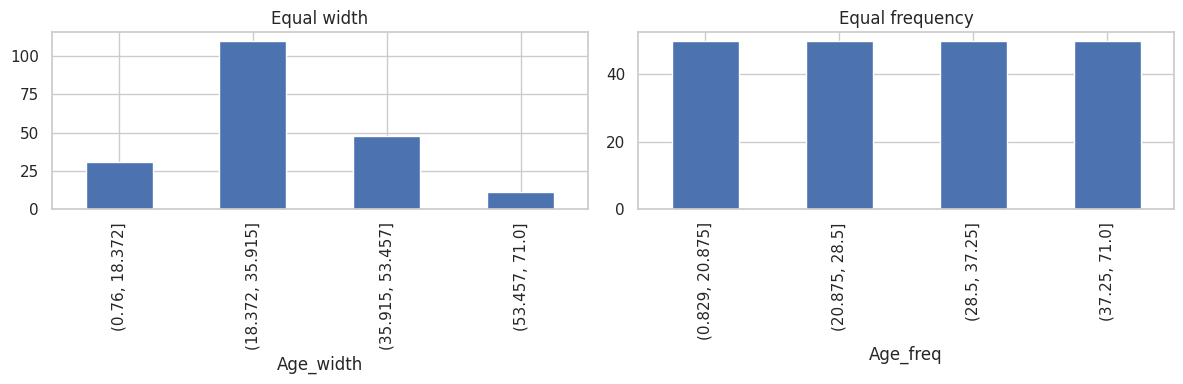

,rate_selamat
Age_freq,
"(0.829, 20.875]",0.52
"(20.875, 28.5]",0.24
"(28.5, 37.25]",0.50
"(37.25, 71.0]",0.36


In [22]:
df_t['Age_width'] = pd.cut(df_t['Age'], bins=4)
df_t['Age_freq']  = pd.qcut(df_t['Age'], q=4, duplicates='drop')
a = df_t['Age_width'].value_counts().sort_index(); b = df_t['Age_freq'].value_counts().sort_index()
display(a.to_frame('equal width (pd.cut)')); display(b.to_frame('equal frequency (pd.qcut)'))
fig,ax = plt.subplots(1,2,figsize=(12,4))
a.plot.bar(ax=ax[0], title='Equal width'); b.plot.bar(ax=ax[1], title='Equal frequency'); plt.tight_layout(); plt.show()
display(df_t.groupby('Age_freq')['Survived'].mean().round(3).to_frame('rate_selamat'))

Perbandingan: equal width menghasilkan lebar sama tetapi jumlah data tidak seimbang (menumpuk di usia dewasa muda); equal frequency memberi jumlah tiap kelompok hampir sama dengan lebar rentang berbeda.

Rekayasa fitur: Title, FamilySize, Cabin

In [23]:
df_t['Title'] = df_t['Name'].str.extract(r',\s*([^\.]+)\.')[0].str.strip()
df_t['Title'] = df_t['Title'].replace({'Mlle':'Miss','Ms':'Miss','Mme':'Mrs'})
common = df_t['Title'].value_counts()[lambda s: s>=10].index
df_t['Title_group'] = df_t['Title'].where(df_t['Title'].isin(common), 'Rare')
df_t['FamilySize'] = df_t['SibSp'] + df_t['Parch'] + 1
df_t['IsAlone'] = (df_t['FamilySize']==1).astype(int)
df_t['HasCabin'] = df_t['Cabin'].notna().astype(int)
df_t['Deck'] = df_t['Cabin'].str.strip().str[0].fillna('U')
display(df_t['Title'].value_counts().to_frame('jumlah').T)
display(df_t[['Name','Title','Title_group','SibSp','Parch','FamilySize','Cabin','HasCabin','Deck']].head(8))
display(df_t.groupby('HasCabin')['Survived'].mean().round(3).to_frame('rate_selamat'))

Title,Mr,Miss,Mrs,Master,Dr,Rev,Don,Jonkheer,Sir,Major
jumlah,111,42,33,7,2,1,1,1,1,1


,Name,Title,Title_group,SibSp,Parch,FamilySize,Cabin,HasCabin,Deck
0,"Moubarek, Master. Halim Gonios (""William George"")",Master,Rare,1.0,1.0,3.0,NaN,0,U
1,"Kvillner, Mr. Johan Henrik Johannesson",Mr,Mr,0.0,0.0,1.0,NaN,0,U
2,"Alhomaki, Mr. Ilmari Rudolf",Mr,Mr,0.0,0.0,1.0,NaN,0,U
3,"Harper, Miss. Annie Jessie ""Nina""",Miss,Miss,0.0,1.0,2.0,NaN,0,U
4,"Nicola-Yarred, Miss. Jamila",Miss,Miss,1.0,0.0,2.0,NaN,0,U
5,"Barber, Miss. Ellen ""Nellie""",Miss,Miss,0.0,0.0,1.0,NaN,0,U
6,"Kelly, Miss. Anna Katherine ""Annie Kate""",Miss,Miss,0.0,0.0,1.0,NaN,0,U
7,"Vander Planke, Mr. Leo Edmondus",Mr,Mr,2.0,0.0,3.0,NaN,0,U


,rate_selamat
HasCabin,
0,0.297
1,0.712


Agregasi per Pclass

In [24]:
display(df_t.groupby('Pclass')[['Age','Fare','SibSp','Parch','FamilySize','Survived']].mean().round(3))

,Age,Fare,SibSp,Parch,FamilySize,Survived
Pclass,,,,,,
1.0,38.930,72.793,0.351,0.351,1.702,0.684
2.0,31.387,20.091,0.351,0.324,1.676,0.432
3.0,24.821,13.719,0.472,0.425,1.896,0.245


Smoothing: moving average Fare

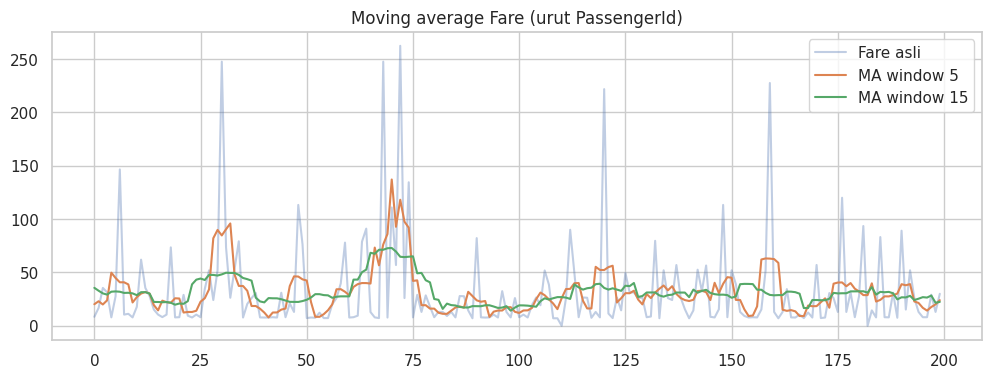

,PassengerId,Fare,Fare_MA5,Fare_MA15
0,6,8.46,20.22,35.59
1,11,16.70,23.01,32.88
2,24,35.50,19.99,30.38
3,26,31.39,23.84,29.24
4,30,7.90,49.80,31.97
5,31,27.72,44.80,32.24
6,32,146.52,40.78,31.93
7,34,10.50,40.77,30.82


In [25]:
s = df_t.sort_values('PassengerId').reset_index(drop=True)
s['Fare_MA5']  = s['Fare'].rolling(5,  center=True, min_periods=1).mean()
s['Fare_MA15'] = s['Fare'].rolling(15, center=True, min_periods=1).mean()
plt.figure(figsize=(12,4))
plt.plot(s['Fare'], alpha=.35, label='Fare asli'); plt.plot(s['Fare_MA5'], label='MA window 5'); plt.plot(s['Fare_MA15'], label='MA window 15')
plt.legend(); plt.title('Moving average Fare (urut PassengerId)'); plt.show()
display(s[['PassengerId','Fare','Fare_MA5','Fare_MA15']].head(8).round(2))

5. REDUKASI DATA

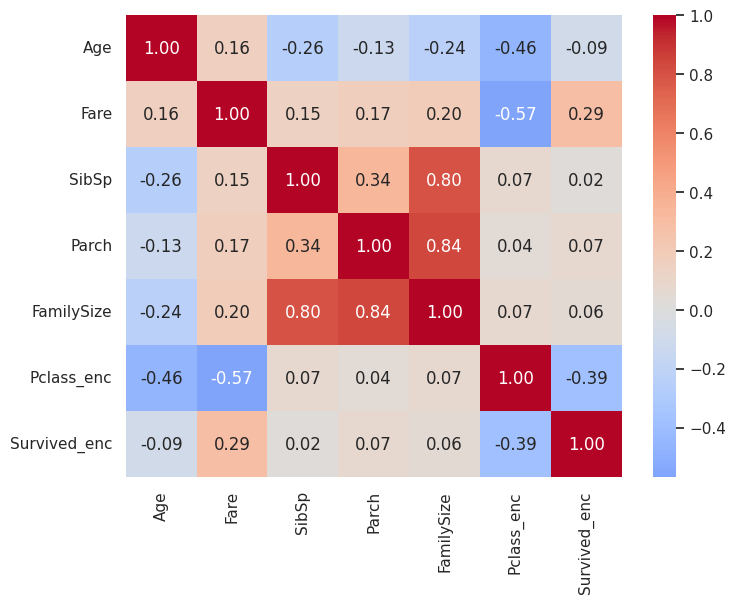

Pasangan berkorelasi tinggi (|r| >= 0.6): [('SibSp', 'FamilySize', np.float64(0.801)), ('Parch', 'FamilySize', np.float64(0.836))]


In [26]:
num_cols = ['Age','Fare','SibSp','Parch','FamilySize','Pclass_enc','Survived_enc']
corr = df_t[num_cols].corr()
plt.figure(figsize=(8,6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.show()
pairs = [(a,b,round(corr.loc[a,b],3)) for i,a in enumerate(num_cols) for b in num_cols[i+1:] if abs(corr.loc[a,b])>=0.6]
print('Pasangan berkorelasi tinggi (|r| >= 0.6):', pairs)

Redundan: FamilySize adalah kombinasi linear SibSp + Parch + 1, sehingga berkorelasi sangat tinggi dengan keduanya (redundan). Dalam PCA, gunakan SibSp dan Parch saja (atau FamilySize saja) agar informasi keluarga tidak terhitung dua kali.

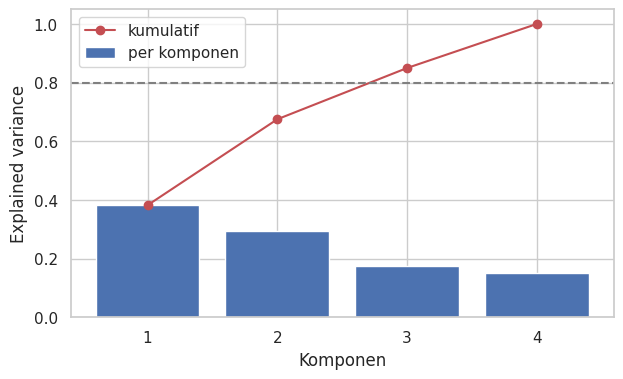

,explained,kumulatif
PC1,0.382,0.382
PC2,0.293,0.675
PC3,0.175,0.850
PC4,0.150,1.000


Komponen dipertahankan: 3 (kumulatif 85.0%, ambang 80%)


,PC1,PC2,PC3,PC4
Age,-0.391,0.652,0.387,0.522
Fare,0.255,0.741,-0.509,-0.357
SibSp,0.650,-0.043,-0.241,0.719
Parch,0.599,0.157,0.730,-0.288


PC1: dipengaruhi terutama oleh ['SibSp', 'Parch']
PC2: dipengaruhi terutama oleh ['Fare', 'Age']
PC3: dipengaruhi terutama oleh ['Parch', 'Fare']
Bentuk data tereduksi: (200, 3)


In [27]:
pca_cols = ['Age','Fare','SibSp','Parch']
Z = StandardScaler().fit_transform(df_t[pca_cols].astype(float))
pca = PCA().fit(Z)
ev = pca.explained_variance_ratio_; cum = ev.cumsum()
plt.figure(figsize=(7,4))
plt.bar(range(1,len(ev)+1), ev, label='per komponen'); plt.plot(range(1,len(ev)+1), cum, 'o-r', label='kumulatif')
plt.axhline(0.8, ls='--', c='gray'); plt.xticks(range(1,len(ev)+1)); plt.xlabel('Komponen'); plt.ylabel('Explained variance'); plt.legend(); plt.show()
display(pd.DataFrame({'explained':ev.round(3),'kumulatif':cum.round(3)}, index=[f'PC{i+1}' for i in range(len(ev))]))
k = int(np.argmax(cum >= 0.80) + 1)
print(f'Komponen dipertahankan: {k} (kumulatif {cum[k-1]:.1%}, ambang 80%)')
load = pd.DataFrame(pca.components_.T, index=pca_cols, columns=[f'PC{i+1}' for i in range(len(pca_cols))]).round(3)
display(load)
for i in range(k):
    top = load.iloc[:,i].abs().sort_values(ascending=False).index[:2].tolist()
    print(f'PC{i+1}: dipengaruhi terutama oleh {top}')
Z_red = PCA(n_components=k).fit_transform(Z)
print('Bentuk data tereduksi:', Z_red.shape)

Interpretasi (isi sesuai output loading): komponen dengan loading besar pada SibSp dan Parch (tanda sama) merepresentasikan ukuran keluarga; komponen dengan loading dominan pada Fare dan Age (tanda berlawanan) merepresentasikan status ekonomi/usia. Jumlah komponen dipilih berdasarkan ambang varians kumulatif ≥ 80% dan elbow pada grafik.

Tabel perbandingan sebelum vs sesudah preprocessing

In [28]:
df_final = df_t.drop(columns=['Name','Ticket','Cabin','PassengerId','Pclass','Survived','Sex','Embarked','Age_width','Age_freq','Title'])
df_final['Survived'] = df_t['Survived_enc']
perb = pd.DataFrame({
    'Sebelum (mentah)': [df_raw.shape[0], df_raw.shape[1], int(df_raw.isna().sum().sum()), int(df_raw['PassengerId'].duplicated().sum())],
    'Sesudah (siap model)': [df_final.shape[0], df_final.shape[1], int(df_final.isna().sum().sum()), int(df_t['PassengerId'].duplicated().sum())]},
    index=['Jumlah baris','Jumlah kolom','Total missing value','PassengerId ganda'])
display(perb)
df_final.to_csv('data_titanic_bersih.csv', index=False)
display(df_final.head())

,Sebelum (mentah),Sesudah (siap model)
Jumlah baris,208,200
Jumlah kolom,15,16
Total missing value,236,0
PassengerId ganda,8,0


,Age,SibSp,Parch,Fare,Pclass_enc,Survived_enc,Sex_enc,Embarked_C,Embarked_Q,Embarked_S,Title_group,FamilySize,IsAlone,HasCabin,Deck,Survived
0,25.0,1.0,1.0,15.2458,2,1,0,1,0,0,Rare,3.0,0,0,U,1
1,31.0,0.0,0.0,10.5000,1,0,0,0,0,1,Mr,1.0,1,0,U,0
2,20.0,0.0,0.0,7.9250,2,0,0,0,0,1,Mr,1.0,1,0,U,0
3,34.5,0.0,1.0,13.0000,1,1,1,0,0,1,Miss,2.0,0,0,U,1
4,14.0,1.0,0.0,11.2417,2,1,1,1,0,0,Miss,2.0,0,0,U,1
